# CSCI 635: Intro to Machine Learning - Final Project
**Name:** Group 5 (Lorenzo Tantalo's implementation)     
**Date:** October 28, 2026  
**Class:** CSCI 635 (Intro to Machine Learning)  
**Subject:** Computer Vision Object Detection and Multiclass Classification on Squirrels

**Description:**  
This notebook implements a data engineering and deep learning pipeline to fine-tune a YOLO26m (Medium) object detection model. The model is trained on an 11-class dataset of squirrel images (converted from COCO to YOLO format) utilizing a 70/15/15 train/valid/test split, with rigorous leakage mitigation (pHash perceptual deduplication) already done. The pipeline includes automated maximum batch-size profiling, hyperparameter optimization (Cosine Annealing), robust training loops with checkpointing, advanced Exploratory Data Analysis (EDA) for bounding box spatial/RGB distributions, and comprehensive evaluation metrics (mAP@50-95, Precision, Recall) across training, validation, and test sets.

## 1. Setup and File Path Resolution

In [32]:
import os
import glob
import re
from ultralytics import YOLO

# --- Configuration ---
data_yaml = r"C:\Users\loren\Computer Science\CSCI_635_Intro_to_Machine_Learning\CSCI-635-ML-Project\data\squirrel-v2-audited-yolo\96af70a0474fdebe\data.yaml"

# Set this to the absolute path where the runs are physically stored
project_dir = r"C:\Users\loren\Computer Science\CSCI_635_Intro_to_Machine_Learning\CSCI-635-ML-Project\runs\detect\squirrel_detection"

run_prefix = "yolo26_run_"

# --- Dynamic Folder Naming Logic ---
existing_runs = glob.glob(os.path.join(project_dir, f"{run_prefix}*"))

latest_run_num = 0
latest_run_dir = None

if existing_runs:
    for run_path in existing_runs:
        folder_name = os.path.basename(run_path)
        suffix = folder_name.replace(run_prefix, "")
        
        match = re.search(r'^(\d+)', suffix)
        if match:
            num = int(match.group(1))
            if num > latest_run_num:
                latest_run_num = num
                
    latest_run_dir = max(existing_runs, key=os.path.getctime)
else:
    latest_run_dir = "None (First Run)"

next_run_name = f"{run_prefix}{latest_run_num + 1}"

print(f"Latest run detected: {latest_run_dir}")
print(f"Next run will be saved as: {project_dir}\\{next_run_name}")

Latest run detected: C:\Users\loren\Computer Science\CSCI_635_Intro_to_Machine_Learning\CSCI-635-ML-Project\runs\detect\squirrel_detection\yolo26_run_4
Next run will be saved as: C:\Users\loren\Computer Science\CSCI_635_Intro_to_Machine_Learning\CSCI-635-ML-Project\runs\detect\squirrel_detection\yolo26_run_5


## 2. EDA and Dataset Demographics

In [3]:
!uv pip install seaborn

Using Python 3.13.16 environment at: c:\Users\loren\Computer Science\CSCI_635_Intro_to_Machine_Learning\CSCI-635-ML-Project\.venv
Resolved 15 packages in 1.13s
Prepared 1 package in 370ms
Installed 1 package in 158ms
 + seaborn==0.13.2


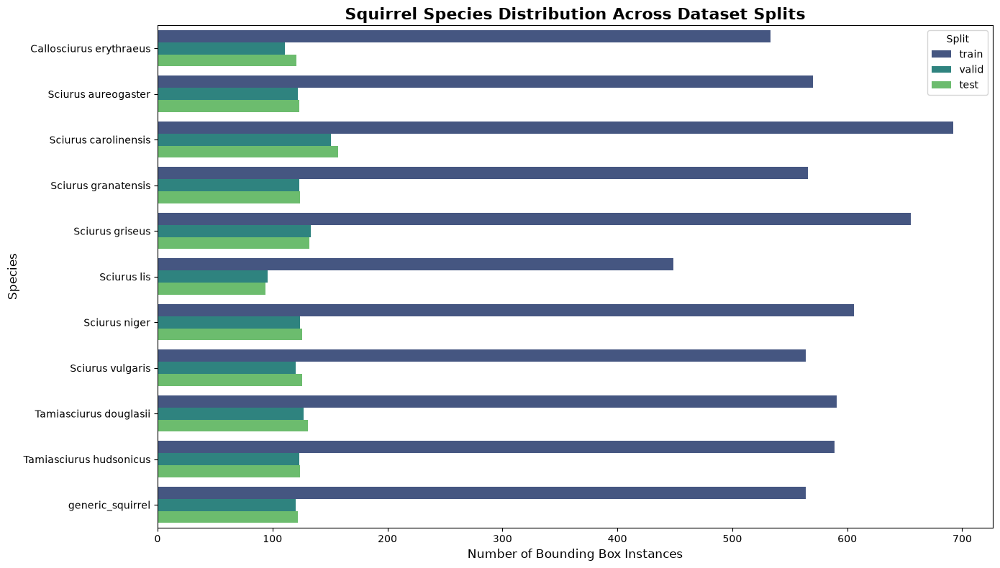

In [4]:
import os
import glob
import yaml
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- Configuration ---
data_dir = os.path.dirname(data_yaml)

# Load class names
with open(data_yaml, 'r') as f:
    data_dict = yaml.safe_load(f)
class_names = data_dict['names']

splits = ['train', 'valid', 'test']
distribution = {split: {i: 0 for i in range(len(class_names))} for split in splits}

# Parse label files to count instances
for split in splits:
    label_dir = os.path.join(data_dir, 'labels', split)
    for label_file in glob.glob(os.path.join(label_dir, "*.txt")):
        with open(label_file, 'r') as f:
            for line in f:
                class_id = int(line.split()[0])
                distribution[split][class_id] += 1

# Transform to DataFrame for plotting
df = pd.DataFrame(distribution).fillna(0)
df.index = df.index.map(class_names)
df = df.reset_index().melt(id_vars='index', var_name='Split', value_name='Count')
df.rename(columns={'index': 'Species'}, inplace=True)

# Plotting
plt.figure(figsize=(14, 8))
sns.barplot(data=df, x='Count', y='Species', hue='Split', palette='viridis')
plt.title('Squirrel Species Distribution Across Dataset Splits', fontsize=16, fontweight='bold')
plt.xlabel('Number of Bounding Box Instances', fontsize=12)
plt.ylabel('Species', fontsize=12)
plt.tight_layout()
plt.show()

Extracting spatial and RGB data from all bounding boxes...


C:\Users\loren\AppData\Local\Temp\ipykernel_32328\590201961.py:76: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda, x='area', y='Species', palette='Set2', ax=ax2)


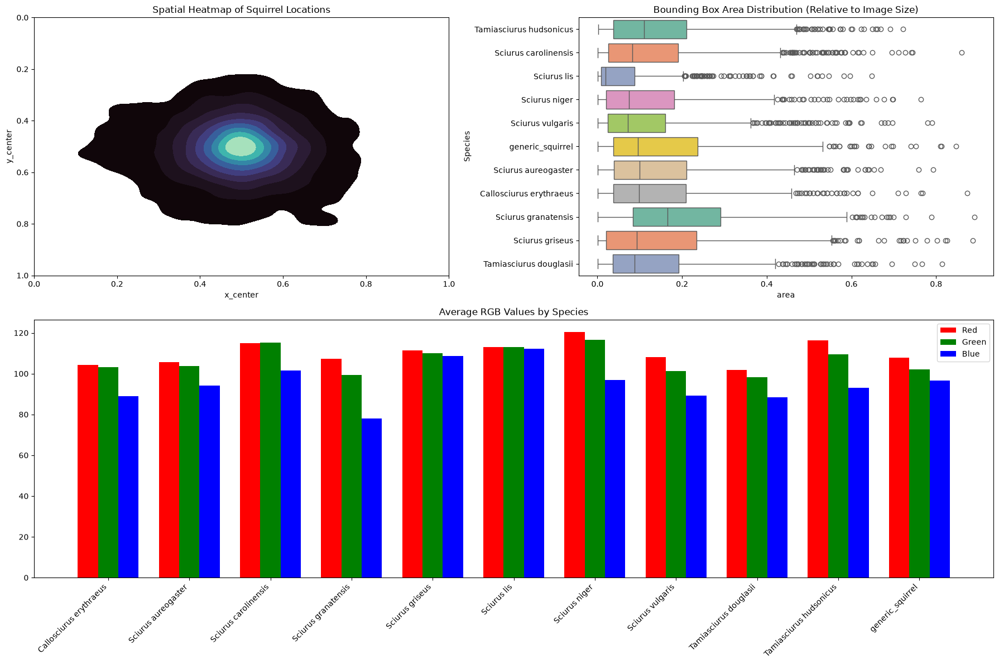

In [5]:
import os
import glob
import yaml
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- Configuration ---

with open(data_yaml, 'r') as f:
    class_names = yaml.safe_load(f)['names']

bbox_data = []

print("Extracting spatial and RGB data from all bounding boxes...")
for split in ['train', 'valid', 'test']:
    img_dir = os.path.join(data_dir, 'images', split)
    label_dir = os.path.join(data_dir, 'labels', split)
    
    for label_file in glob.glob(os.path.join(label_dir, "*.txt")):
        base_name = os.path.splitext(os.path.basename(label_file))[0]
        img_file = os.path.join(img_dir, f"{base_name}.jpg")
        
        if not os.path.exists(img_file):
            continue
            
        img = cv2.imread(img_file)
        if img is None: continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w, _ = img.shape
        
        with open(label_file, 'r') as f:
            for line in f:
                parts = line.strip().split()
                cls_id = int(parts[0])
                x_c, y_c, bw, bh = map(float, parts[1:5])
                
                # Spatial data
                area = bw * bh
                
                # Extract RGB from the cropped box
                x_min, y_min = int((x_c - bw/2) * w), int((y_c - bh/2) * h)
                x_max, y_max = int((x_c + bw/2) * w), int((y_c + bh/2) * h)
                
                # Clamp coordinates to image boundaries
                x_min, y_min = max(0, x_min), max(0, y_min)
                x_max, y_max = min(w, x_max), min(h, y_max)
                
                crop = img[y_min:y_max, x_min:x_max]
                if crop.size == 0: continue
                
                mean_r, mean_g, mean_b = crop.mean(axis=(0,1))
                
                bbox_data.append({
                    'Split': split, 'Species': class_names[cls_id],
                    'x_center': x_c, 'y_center': y_c, 
                    'width': bw, 'height': bh, 'area': area,
                    'R': mean_r, 'G': mean_g, 'B': mean_b
                })

df_eda = pd.DataFrame(bbox_data)

# --- Visualizations ---
fig = plt.figure(figsize=(18, 12))

# 1. Spatial Heatmap
ax1 = plt.subplot(2, 2, 1)
sns.kdeplot(data=df_eda, x='x_center', y='y_center', fill=True, cmap='mako', ax=ax1)
ax1.set_title("Spatial Heatmap of Squirrel Locations")
ax1.set_xlim(0, 1); ax1.set_ylim(1, 0) # Invert Y to match image coordinates

# 2. Bounding Box Areas by Species
ax2 = plt.subplot(2, 2, 2)
sns.boxplot(data=df_eda, x='area', y='Species', palette='Set2', ax=ax2)
ax2.set_title("Bounding Box Area Distribution (Relative to Image Size)")

# 3. Average RGB values
df_rgb = df_eda.groupby('Species')[['R', 'G', 'B']].mean().reset_index()
ax3 = plt.subplot(2, 1, 2)
x_indexes = np.arange(len(df_rgb))
width = 0.25
ax3.bar(x_indexes - width, df_rgb['R'], width=width, color='red', label='Red')
ax3.bar(x_indexes, df_rgb['G'], width=width, color='green', label='Green')
ax3.bar(x_indexes + width, df_rgb['B'], width=width, color='blue', label='Blue')
ax3.set_xticks(x_indexes)
ax3.set_xticklabels(df_rgb['Species'], rotation=45, ha='right')
ax3.set_title("Average RGB Values by Species")
ax3.legend()

plt.tight_layout()
plt.show()

## 3. The Training Engine

In [35]:
# --- Execution Toggle ---
# Set to True if your Jupyter kernel dies, your PC restarts, or you stop the cell manually
RESUME_TRAINING = False 

if RESUME_TRAINING:
    if latest_run_num == 0:
        print("Error: No previous runs found to resume.")
    else:
        print(f"Resuming training in the existing folder: {latest_run_dir}")
        
        # Target the 'last.pt' file
        last_checkpoint = os.path.join(latest_run_dir, "weights", "last.pt")
        #last_checkpoint = r"C:\Users\loren\Computer Science\CSCI_635_Intro_to_Machine_Learning\CSCI-635-ML-Project\runs\detect\squirrel_detection\yolo26_run_1-2\weights\last.pt"

        # Load the interrupted model state
        model = YOLO(last_checkpoint)
        
        # Pass ONLY resume=True. The model will handle its own paths internally.
        results = model.train(resume=True)

else:
    print(f"Starting fresh training round. Outputting to: {project_dir}/{next_run_name}")
    
    # 1. Initialize the YOLO26 Medium Model
    model = YOLO("yolo26m.pt")
    
    # 2. Start the Training Engine
    results = model.train(
        data=data_yaml,
        project=project_dir,
        name=next_run_name,
        
        epochs=100,
        patience=30,
        
        # --- AutoBatch GPU Maximization ---
        # Setting batch to -1 tells Ultralytics to simulate a forward pass before training. 
        # It calculates exactly how much VRAM YOLO26m requires at 640px and maxes out your 
        # batch size to hit ~60% GPU utilization, ensuring stability.
        #batch=-1, 
        
        imgsz=640,
        device=0, 
        
        optimizer="auto",
        lr0=0.01,
        lrf=0.01,
        cos_lr=True,
        
        # Data Augmentation
        mosaic=1.0,
        fliplr=0.5,
        scale=0.5,
        hsv_h=0.015,
        hsv_s=0.7,
        hsv_v=0.4,

        seed=42,             # Locks the random number generators
        deterministic=False,  # Forces reproducible GPU math operations

        # --- Stability Fixes ---
        batch=8,             # Hardcoded to prevent the -11GB memory overflow
        workers=0            # Prevents PyTorch multiprocessing crashes on Windows
    )

Starting fresh training round. Outputting to: C:\Users\loren\Computer Science\CSCI_635_Intro_to_Machine_Learning\CSCI-635-ML-Project\runs\detect\squirrel_detection/yolo26_run_5
New https://pypi.org/project/ultralytics/8.4.194 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.164  Python-3.13.16 torch-2.14.1+cu132 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=C:\Users\loren\Computer Science\CSCI_635_Intro_to_Machine_Learning\CSCI-635-ML-Project\data\squirrel-v2-audited-yolo\96af70a0474fdebe\data.yaml, degrees=0.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dy

## 4 .Quantitative Evaluation & Automated Metric Plots (Test Set)

### Latest Model Finder and Training/Validation Progression Analysis

Analyzing training progression for: C:\Users\loren\Computer Science\CSCI_635_Intro_to_Machine_Learning\CSCI-635-ML-Project\runs\detect\squirrel_detection\yolo26_run_5


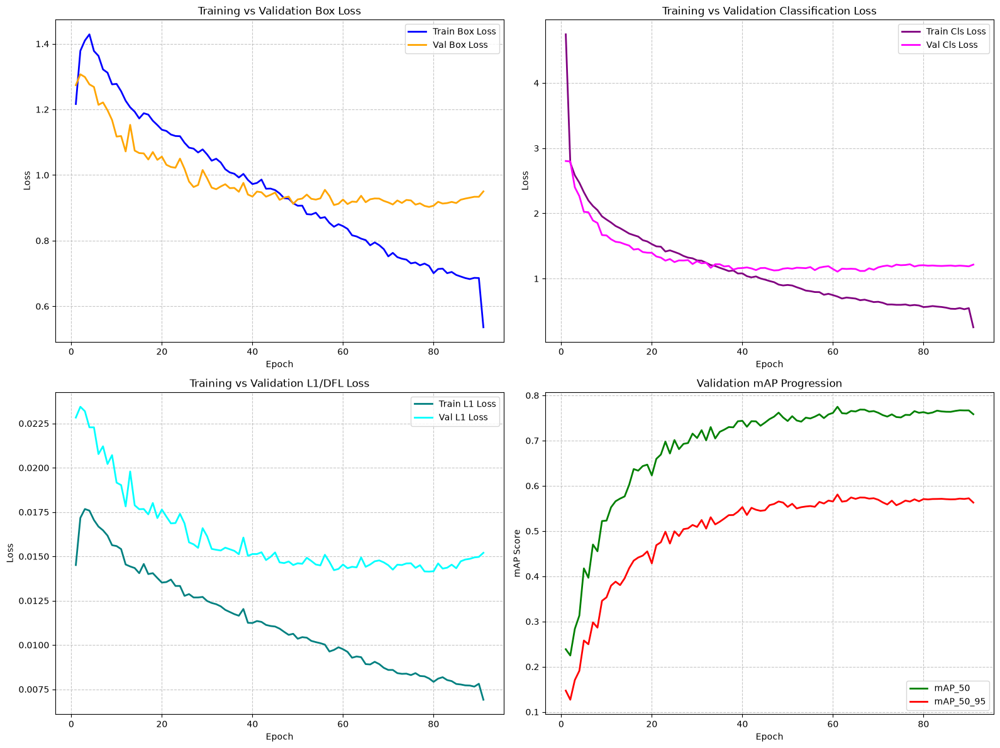

In [40]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# SPECIFY YOUR RUN NUMBER HERE
run_number = 5
target_run_dir = os.path.join(project_dir, f"yolo26_run_{run_number}")

# Validate that the folder exists before proceeding
if not os.path.exists(target_run_dir):
    raise FileNotFoundError(f"Could not find the target directory: {target_run_dir}")

print(f"Analyzing training progression for: {target_run_dir}")

# Load training results
results_path = os.path.join(target_run_dir, "results.csv")
if not os.path.exists(results_path):
    raise FileNotFoundError(f"Could not find results.csv inside {target_run_dir}")

df_results = pd.read_csv(results_path)

# Strip trailing/leading spaces from Ultralytics column names
df_results.columns = df_results.columns.str.strip()

# --- Plot Learning Curves ---
# Expanded to a 2x2 grid to accommodate the extra loss graphs
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: Box Loss (Top Left)
axes[0, 0].plot(df_results['epoch'], df_results['train/box_loss'], label='Train Box Loss', color='blue', linewidth=2)
axes[0, 0].plot(df_results['epoch'], df_results['val/box_loss'], label='Val Box Loss', color='orange', linewidth=2)
axes[0, 0].set_title("Training vs Validation Box Loss")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].legend()
axes[0, 0].grid(True, linestyle='--', alpha=0.7)

# Plot 2: Classification Loss (Top Right)
# Note: YOLO usually logs this as 'train/cls_loss'. If it's missing, it skips plotting.
if 'train/cls_loss' in df_results.columns:
    axes[0, 1].plot(df_results['epoch'], df_results['train/cls_loss'], label='Train Cls Loss', color='purple', linewidth=2)
    axes[0, 1].plot(df_results['epoch'], df_results['val/cls_loss'], label='Val Cls Loss', color='magenta', linewidth=2)
axes[0, 1].set_title("Training vs Validation Classification Loss")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Loss")
axes[0, 1].legend()
axes[0, 1].grid(True, linestyle='--', alpha=0.7)

# Plot 3: L1 Loss (Bottom Left)
# Note: Depending on the exact Ultralytics version, this might be logged as 'dfl_loss' instead. 
# This checks for 'l1_loss' first, falls back to 'dfl_loss' if needed, or displays a warning text.
if 'train/l1_loss' in df_results.columns:
    axes[1, 0].plot(df_results['epoch'], df_results['train/l1_loss'], label='Train L1 Loss', color='teal', linewidth=2)
    axes[1, 0].plot(df_results['epoch'], df_results['val/l1_loss'], label='Val L1 Loss', color='cyan', linewidth=2)
elif 'train/dfl_loss' in df_results.columns:
    axes[1, 0].plot(df_results['epoch'], df_results['train/dfl_loss'], label='Train DFL (L1) Loss', color='teal', linewidth=2)
    axes[1, 0].plot(df_results['epoch'], df_results['val/dfl_loss'], label='Val DFL (L1) Loss', color='cyan', linewidth=2)
else:
    axes[1, 0].text(0.5, 0.5, 'L1/DFL Loss not found in results.csv', ha='center', va='center', fontsize=12)
axes[1, 0].set_title("Training vs Validation L1/DFL Loss")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Loss")
axes[1, 0].legend()
axes[1, 0].grid(True, linestyle='--', alpha=0.7)

# Plot 4: mAP Metrics (Bottom Right)
axes[1, 1].plot(df_results['epoch'], df_results['metrics/mAP50(B)'], label='mAP_50', color='green', linewidth=2)
axes[1, 1].plot(df_results['epoch'], df_results['metrics/mAP50-95(B)'], label='mAP_50_95', color='red', linewidth=2)
axes[1, 1].set_title("Validation mAP Progression")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("mAP Score")
axes[1, 1].legend(loc='lower right')
axes[1, 1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

### Comprehensive Model Evaluation (Train & Val Splits)

In [41]:
import os
from ultralytics import YOLO


# SPECIFY YOUR RUN NUMBER HERE
run_number = 5
target_run_dir = os.path.join(project_dir, f"yolo26_run_{run_number}")

# Validate that the folder and weights exist before proceeding
if not os.path.exists(target_run_dir):
    raise FileNotFoundError(f"Could not find the target directory: {target_run_dir}")

best_model_path = os.path.join(target_run_dir, "weights", "best.pt")
if not os.path.exists(best_model_path):
    raise FileNotFoundError(f"Could not find best.pt weights inside {target_run_dir}\\weights")

print(f"Loading weights from: {best_model_path}")
model = YOLO(best_model_path)

# --- Evaluate on Training Set ---
# We evaluate the train set to check for memorization. If Train mAP is 0.99 
# but Val mAP is 0.45, the model heavily overfit despite regularizations.
print("\n" + "="*50)
print("EVALUATING ON TRAINING SET (70%)")
print("="*50)
train_metrics = model.val(
    data=data_yaml,
    split='train',
    project=project_dir,
    name=f"yolo26_run_{run_number}_eval_train",
    plots=True
)
print(f"Training mAP_50_95: {train_metrics.box.map:.4f}")
print(f"Training Precision: {train_metrics.box.mp:.4f}")
print(f"Training Recall:    {train_metrics.box.mr:.4f}")

# --- Evaluate on Validation Set ---
print("\n" + "="*50)
print("EVALUATING ON VALIDATION SET (15%)")
print("="*50)
val_metrics = model.val(
    data=data_yaml,
    split='val',
    project=project_dir,
    name=f"yolo26_run_{run_number}_eval_val",
    plots=True  # Generates Confusion Matrix, PR Curves, etc.
)
print(f"Validation mAP_50_95: {val_metrics.box.map:.4f}")
print(f"Validation Precision: {val_metrics.box.mp:.4f}")
print(f"Validation Recall:    {val_metrics.box.mr:.4f}")

print("\nEvaluation complete. Advanced metric visuals (Confusion Matrices, Confidence curves) ")
print(f"are saved in: {project_dir}\\yolo26_run_{run_number}_eval_val\\ and _eval_train\\")

Loading weights from: C:\Users\loren\Computer Science\CSCI_635_Intro_to_Machine_Learning\CSCI-635-ML-Project\runs\detect\squirrel_detection\yolo26_run_5\weights\best.pt

EVALUATING ON TRAINING SET (70%)
Ultralytics 8.4.164  Python-3.13.16 torch-2.14.1+cu132 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
YOLO26m summary (fused): 130 layers, 20,357,933 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access  (ping: 1.12.1 ms, read: 352.9178.3 MB/s, size: 378.1 KB)
val: Scanning C:\Users\loren\Computer Science\CSCI_635_Intro_to_Machine_Learning\CSCI-635-ML-Project\data\squirrel-v2-audited-yolo\96af70a0474fdebe\labels\train.cache... 5988 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 5988/5988 1.6Git/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 375/375 3.4s/it 21:057.3ss17
                   all       5988       6379      0.977      0.964      0.989       0.86
Callosciurus erythraeus        501        533 

METRIC COMPARISONS (TRAIN VS VALIDATION)


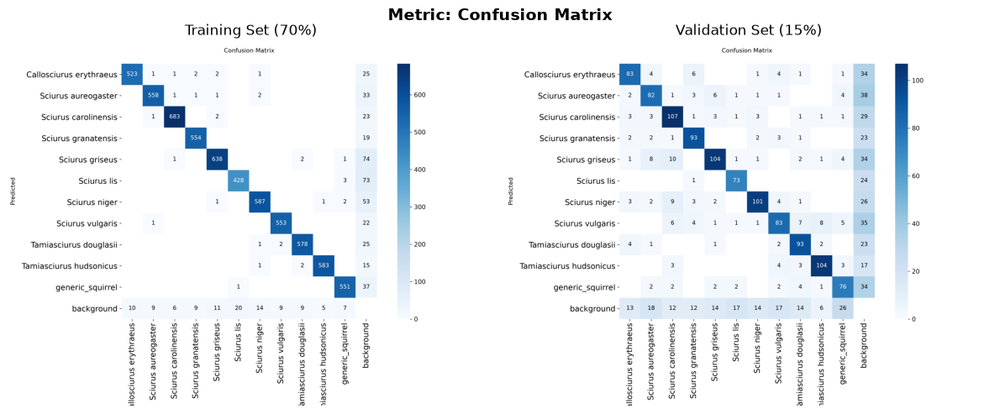

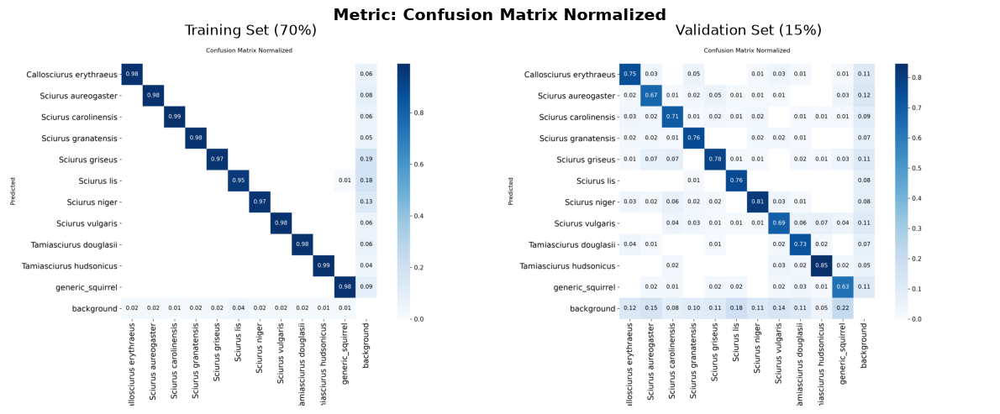

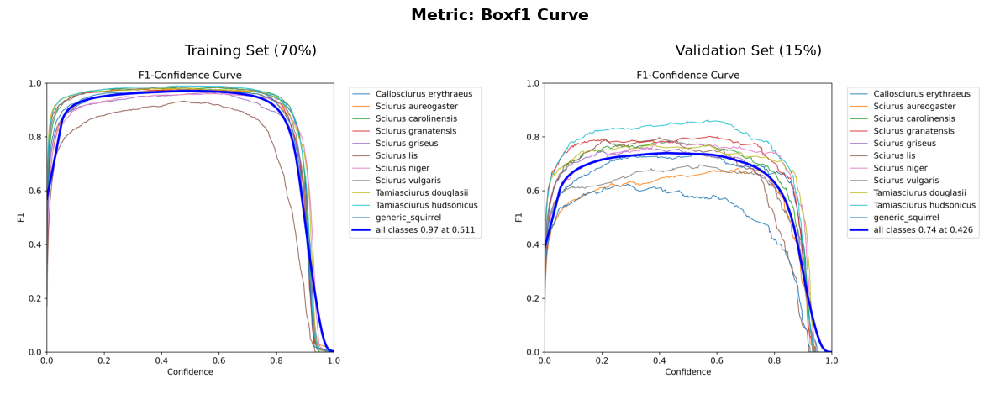

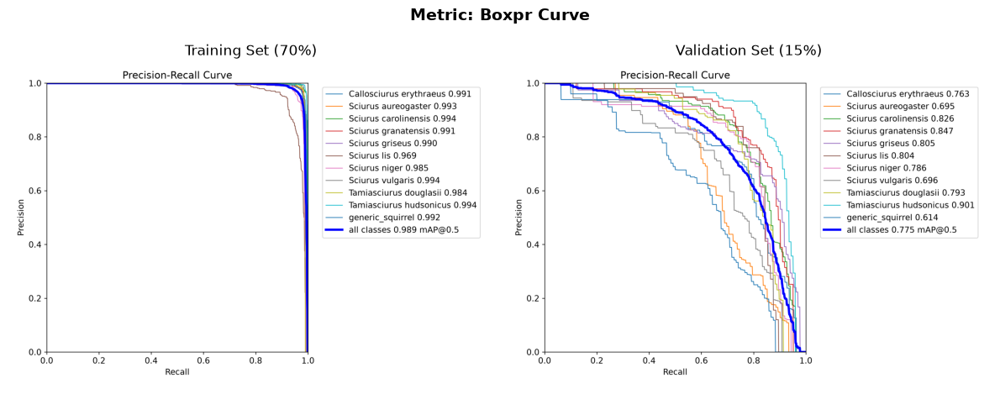

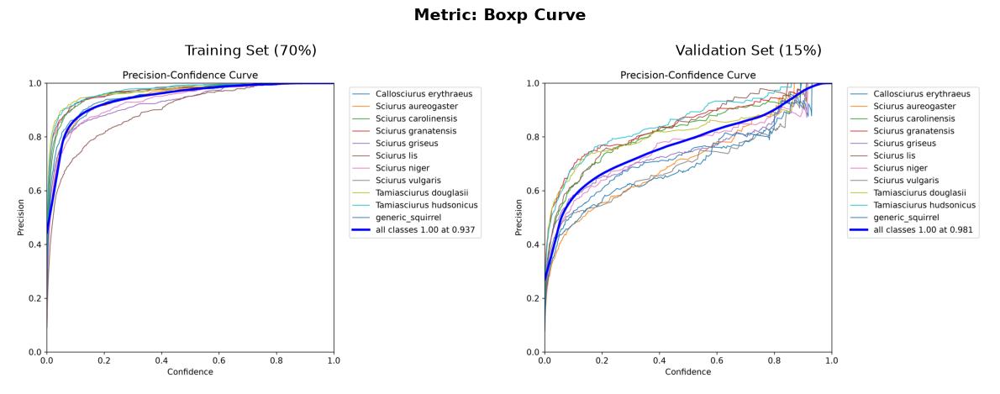

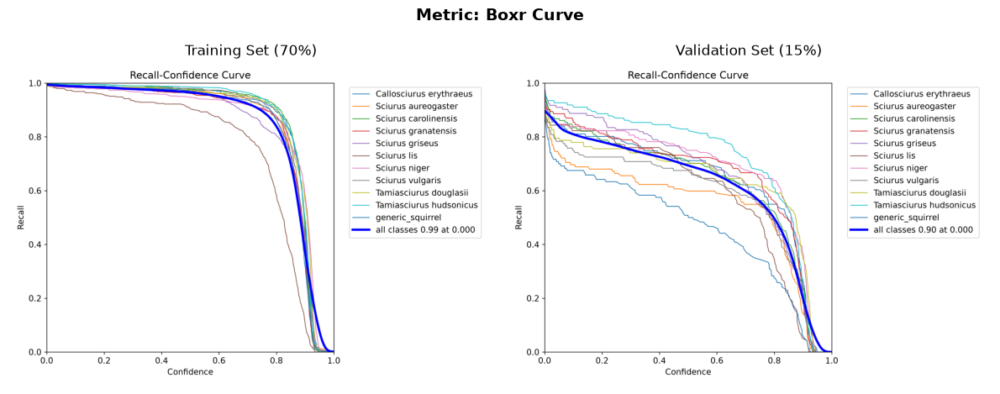


BOUNDING BOX VISUALS (ACTUAL VS PREDICTED)


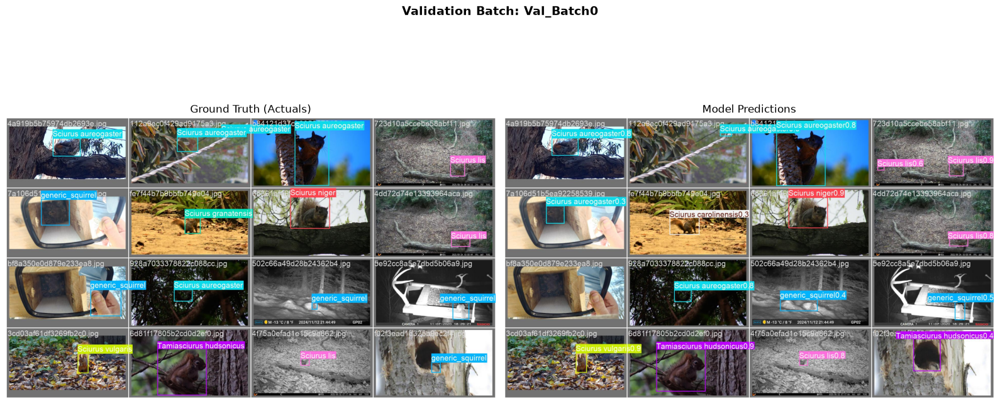

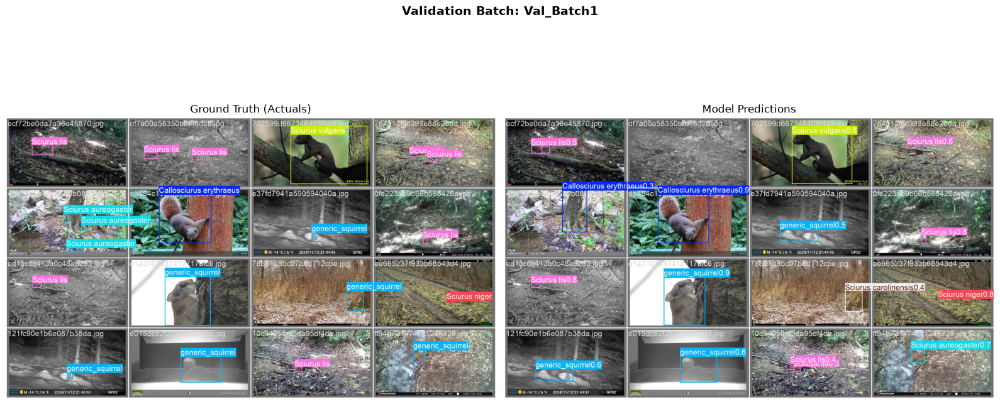

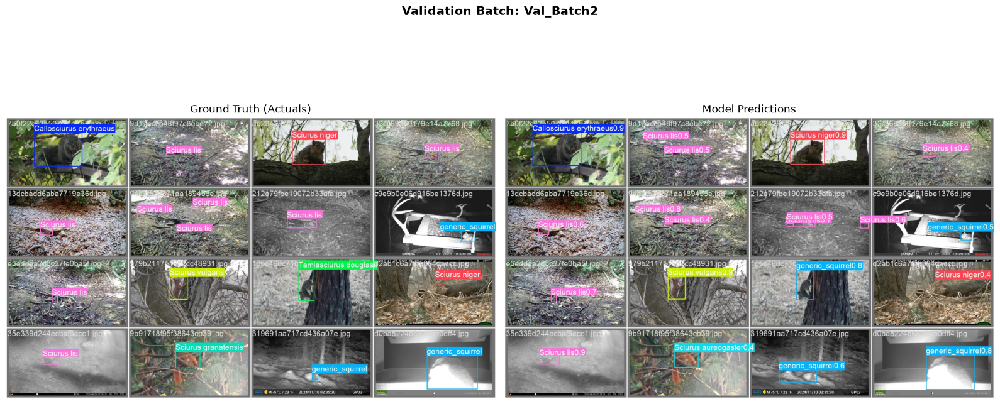

In [44]:
import os
import glob
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# SPECIFY YOUR RUN NUMBER HERE
run_number = 5
train_eval_dir = os.path.join(project_dir, f"yolo26_run_{run_number}_eval_train")
val_eval_dir = os.path.join(project_dir, f"yolo26_run_{run_number}_eval_val")

# =====================================================================
# 1. Compare Train vs Val Metrics (Side-by-Side)
# =====================================================================
metric_files = [
    'confusion_matrix.png', 
    'confusion_matrix_normalized.png', 
    'BoxF1_curve.png', 
    'BoxPR_curve.png', 
    'BoxP_curve.png', 
    'BoxR_curve.png'
]

print("="*60)
print("METRIC COMPARISONS (TRAIN VS VALIDATION)")
print("="*60)

for file_name in metric_files:
    train_path = os.path.join(train_eval_dir, file_name)
    val_path = os.path.join(val_eval_dir, file_name)
    
    # Skip if the file wasn't generated in either directory
    if not os.path.exists(train_path) and not os.path.exists(val_path):
        continue 
        
    # Create a smaller 1x2 grid (12x5 inches)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5)) 
    
    # Clean up the filename for the title
    clean_title = file_name.split('.')[0].replace('_', ' ').title()
    fig.suptitle(f"Metric: {clean_title}", fontsize=14, fontweight='bold')
    
    # Left Side: Training
    if os.path.exists(train_path):
        axes[0].imshow(mpimg.imread(train_path))
        axes[0].set_title("Training Set (70%)")
    else:
        axes[0].text(0.5, 0.5, 'Not Generated', ha='center', va='center')
    axes[0].axis('off')
    
    # Right Side: Validation
    if os.path.exists(val_path):
        axes[1].imshow(mpimg.imread(val_path))
        axes[1].set_title("Validation Set (15%)")
    else:
        axes[1].text(0.5, 0.5, 'Not Generated', ha='center', va='center')
    axes[1].axis('off')
    
    plt.tight_layout()
    plt.show()

# =====================================================================
# 2. Compare Ground Truth vs Predictions (Validation Set)
# =====================================================================
print("\n" + "="*60)
print("BOUNDING BOX VISUALS (ACTUAL VS PREDICTED)")
print("="*60)

# YOLO outputs these batches as 'val_batchX_labels.jpg' and 'val_batchX_pred.jpg'
# We will focus on the Validation set for visual inspection
batch_labels = sorted(glob.glob(os.path.join(val_eval_dir, "*_labels.jpg")))

for label_path in batch_labels:
    # Construct the path to the corresponding prediction image
    pred_path = label_path.replace('_labels', '_pred')
    
    # Slightly larger figure (16x8) so the bounding box text is legible
    fig, axes = plt.subplots(1, 2, figsize=(16, 8)) 
    
    batch_name = os.path.basename(label_path).split('_labels')[0]
    fig.suptitle(f"Validation Batch: {batch_name.title()}", fontsize=14, fontweight='bold')
    
    # Left Side: Ground Truth
    axes[0].imshow(mpimg.imread(label_path))
    axes[0].set_title("Ground Truth (Actuals)")
    axes[0].axis('off')
    
    # Right Side: Predictions
    if os.path.exists(pred_path):
        axes[1].imshow(mpimg.imread(pred_path))
        axes[1].set_title("Model Predictions")
    else:
        axes[1].text(0.5, 0.5, 'Predictions Not Found', ha='center', va='center')
    axes[1].axis('off')
    
    plt.tight_layout()
    plt.show()

In [45]:
import os
import pandas as pd
import numpy as np


run_number = 5
val_eval_dir = os.path.join(project_dir, f"yolo26_run_{run_number}_eval_val")

print("Extracting raw curve data to CSV...")

# YOLO stores the curve names in .curves and the raw arrays in .curves_results
for curve_name, curve_data in zip(val_metrics.curves, val_metrics.curves_results):
    
    # Unpack the internal arrays
    # x_thresholds = 1D array of thresholds (~1000 data points)
    # y_values = 2D array of metrics (Shape: 11 classes, ~1000 data points)
    x_thresholds, y_values, x_title, y_title = curve_data
    
    # 1. Start the CSV with the X-axis (Usually 'Confidence' or 'Recall')
    df = pd.DataFrame({x_title: x_thresholds})
    
    # 2. Add a column for each of your 11 squirrel classes
    for class_idx, class_name in val_metrics.names.items():
        df[class_name] = y_values[class_idx]
        
    # 3. Add the 'All Classes' average (the bold blue line in the plots)
    df["All_Classes_Mean"] = np.mean(y_values, axis=0)
    
    # 4. Clean the internal name so Windows accepts it as a file name
    clean_name = curve_name.replace("/", "_").replace(" ", "_")
    csv_path = os.path.join(val_eval_dir, f"{clean_name}_raw_data.csv")
    
    # Export
    df.to_csv(csv_path, index=False)
    print(f"Saved: {clean_name}_raw_data.csv")

print(f"\nSuccess! All raw data points are now saved inside:\n{val_eval_dir}")

Extracting raw curve data to CSV...
Saved: Precision-Recall(B)_raw_data.csv
Saved: F1-Confidence(B)_raw_data.csv
Saved: Precision-Confidence(B)_raw_data.csv
Saved: Recall-Confidence(B)_raw_data.csv

Success! All raw data points are now saved inside:
C:\Users\loren\Computer Science\CSCI_635_Intro_to_Machine_Learning\CSCI-635-ML-Project\runs\detect\squirrel_detection\yolo26_run_5_eval_val


### Test Set Metrics for Best Selected Model

In [47]:
import os
import pandas as pd
import numpy as np
from ultralytics import YOLO
from IPython.display import Image, display

# SPECIFY YOUR RUN NUMBER HERE
run_number = 5
target_run_dir = os.path.join(project_dir, f"yolo26_run_{run_number}")
best_model_path = os.path.join(target_run_dir, "weights", "best.pt")

if not os.path.exists(best_model_path):
    raise FileNotFoundError(f"Could not find best.pt weights at {best_model_path}")

model = YOLO(best_model_path)
test_eval_name = f"yolo26_run_{run_number}_eval_test"

# --- Evaluate on Test Set ---
print("Starting evaluation on the unseen TEST set...")
test_metrics = model.val(
    data=data_yaml,
    split='test',
    project=project_dir,
    name=test_eval_name,
    plots=True  # Forces generation of all metric graphs
)

# --- Print Core Metrics ---
print("\n" + "="*40)
print("FINAL TEST SET METRICS")
print("="*40)
print(f"mAP@50-95: {test_metrics.box.map:.4f}")
print(f"mAP@50:    {test_metrics.box.map50:.4f}")
print(f"Precision: {test_metrics.box.mp:.4f} (Mean across all classes)")
print(f"Recall:    {test_metrics.box.mr:.4f} (Mean across all classes)")
print("="*40 + "\n")

# --- Extract Raw Curve Data to CSV ---
eval_dir = test_metrics.save_dir
print("Extracting raw curve data to CSV...")

for curve_name, curve_data in zip(test_metrics.curves, test_metrics.curves_results):
    x_thresholds, y_values, x_title, y_title = curve_data
    
    df = pd.DataFrame({x_title: x_thresholds})
    for class_idx, class_name in test_metrics.names.items():
        df[class_name] = y_values[class_idx]
        
    df["All_Classes_Mean"] = np.mean(y_values, axis=0)
    
    clean_name = curve_name.replace("/", "_").replace(" ", "_")
    csv_path = os.path.join(eval_dir, f"{clean_name}_raw_data.csv")
    df.to_csv(csv_path, index=False)
    print(f"Saved: {clean_name}_raw_data.csv")

print(f"\nAll test metrics and CSVs saved to: {eval_dir}")

Starting evaluation on the unseen TEST set...
Ultralytics 8.4.164  Python-3.13.16 torch-2.14.1+cu132 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
YOLO26m summary (fused): 130 layers, 20,357,933 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 309.6140.6 MB/s, size: 346.7 KB)
val: Scanning C:\Users\loren\Computer Science\CSCI_635_Intro_to_Machine_Learning\CSCI-635-ML-Project\data\squirrel-v2-audited-yolo\96af70a0474fdebe\labels\test.cache... 1284 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1284/1284 299.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 81/81 5.4s/it 7:216.7ss:27
                   all       1284       1380      0.775      0.698      0.763      0.568
Callosciurus erythraeus        108        121      0.716      0.628      0.694      0.542
   Sciurus aureogaster        114        123      0.705      0.661      0.686      0.485
  Sciurus carolinensis   

METRIC VISUALS (FINAL TEST SET)


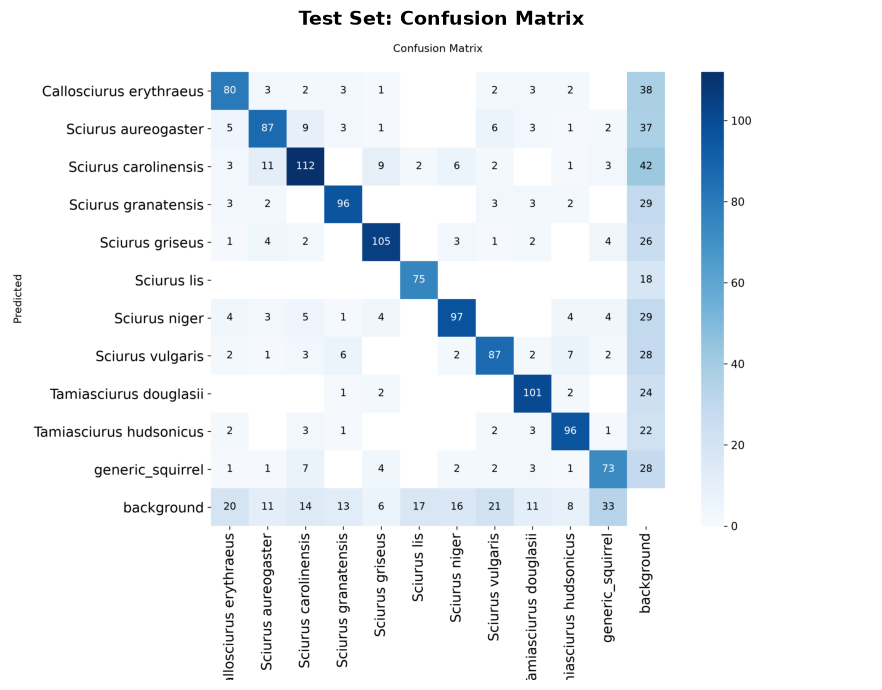

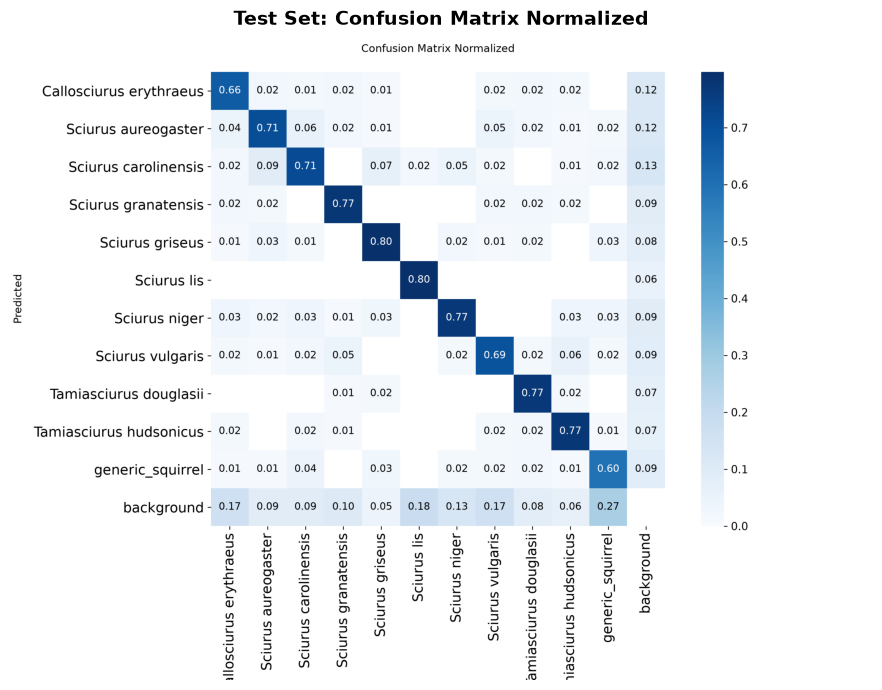

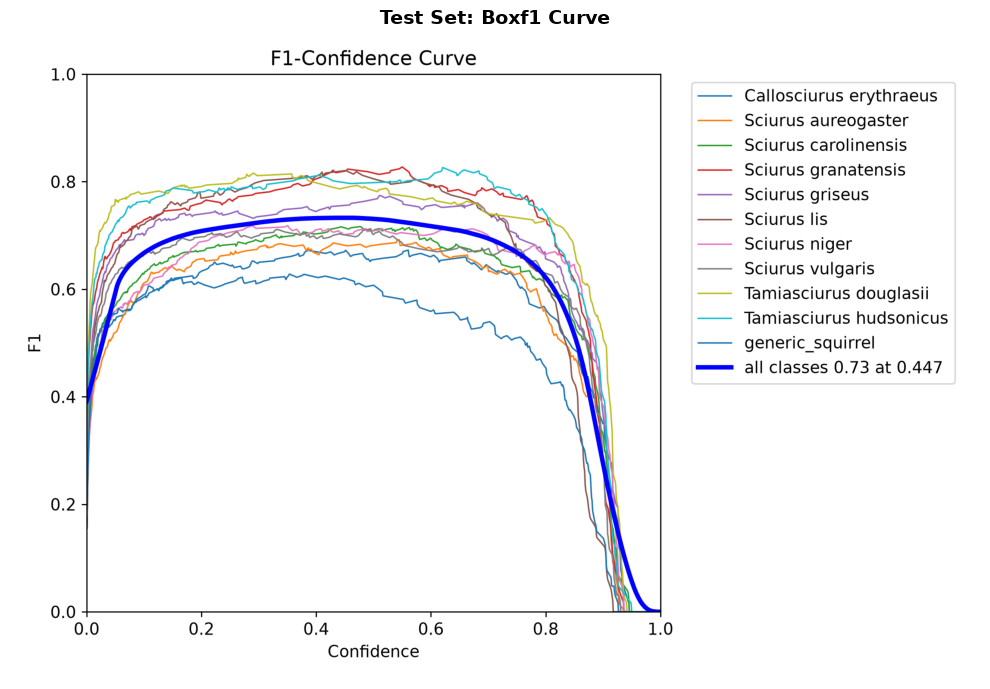

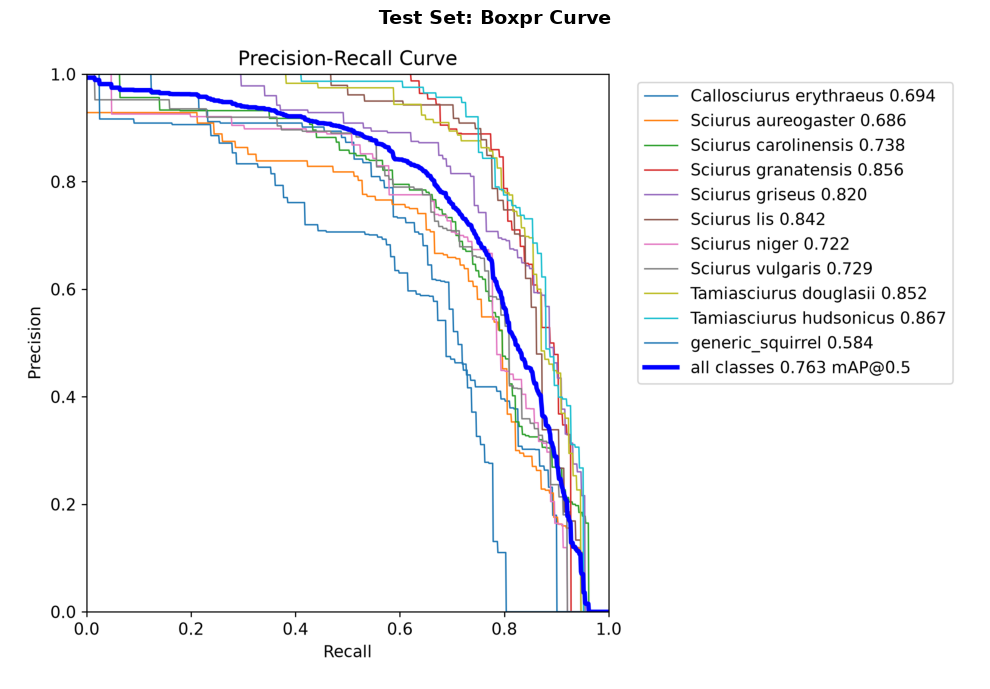

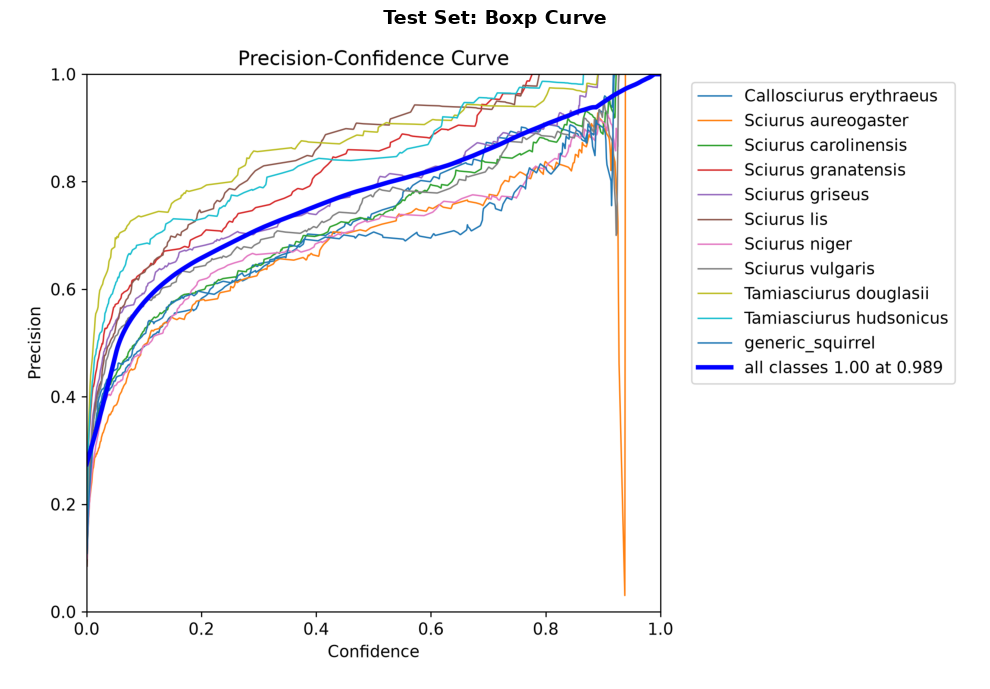

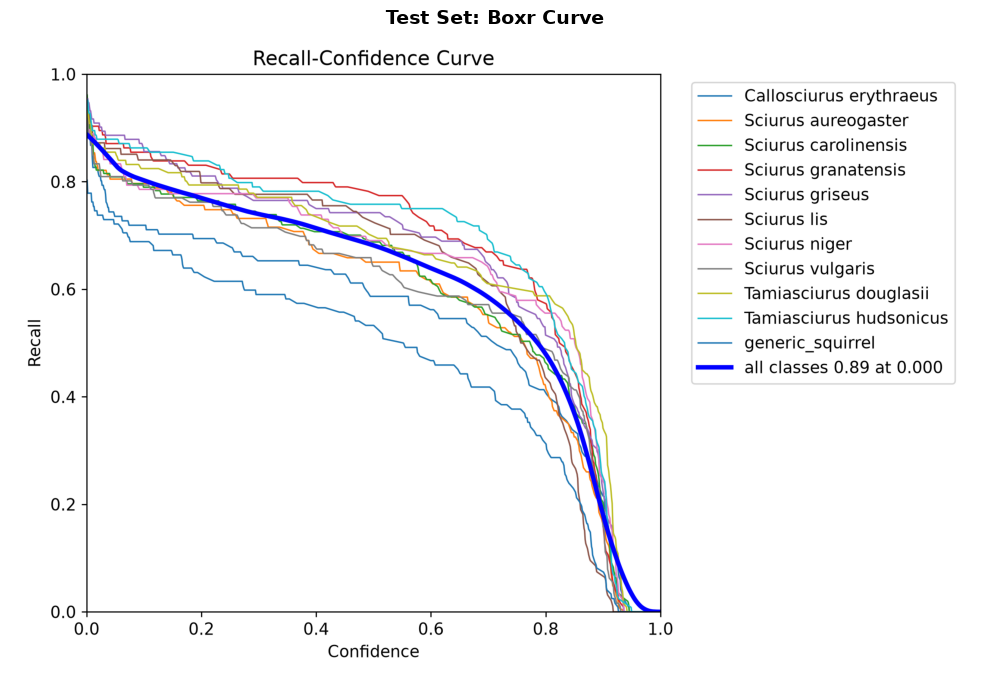


BOUNDING BOX VISUALS (ACTUAL VS PREDICTED ON TEST SET)


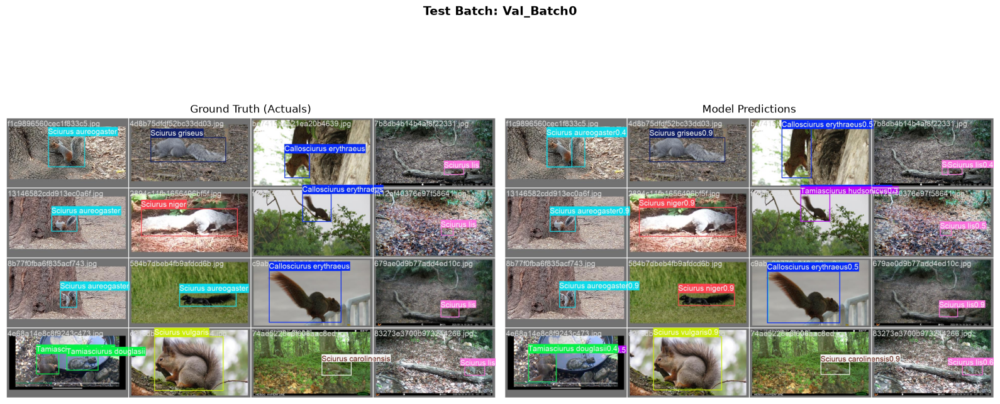

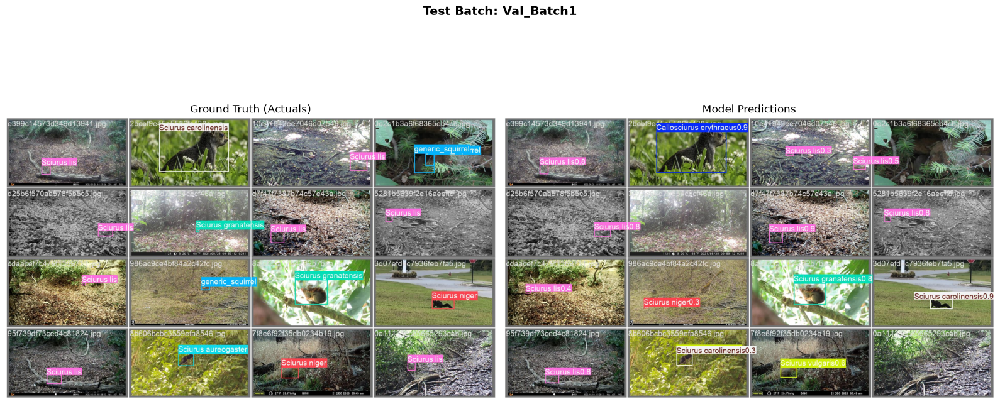

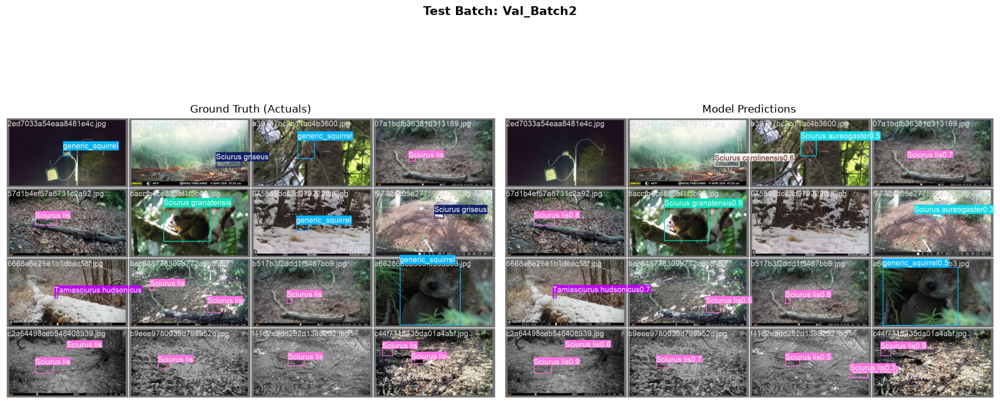

In [48]:
import os
import glob
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# SPECIFY YOUR RUN NUMBER HERE
run_number = 5
test_eval_dir = os.path.join(project_dir, f"yolo26_run_{run_number}_eval_test")

# Validate directory exists
if not os.path.exists(test_eval_dir):
    raise FileNotFoundError(f"Could not find test directory: {test_eval_dir}")

# =====================================================================
# 1. View Test Set Metrics
# =====================================================================
metric_files = [
    'confusion_matrix.png', 
    'confusion_matrix_normalized.png', 
    'BoxF1_curve.png', 
    'BoxPR_curve.png', 
    'BoxP_curve.png', 
    'BoxR_curve.png'
]

print("="*60)
print("METRIC VISUALS (FINAL TEST SET)")
print("="*60)

for file_name in metric_files:
    test_path = os.path.join(test_eval_dir, file_name)
    
    # Skip if the file wasn't generated
    if not os.path.exists(test_path):
        continue 
        
    # Create a single plot for the test metric (10x7 inches)
    fig, ax = plt.subplots(figsize=(10, 7)) 
    
    # Clean up the filename for the title
    clean_title = file_name.split('.')[0].replace('_', ' ').title()
    ax.set_title(f"Test Set: {clean_title}", fontsize=14, fontweight='bold')
    
    ax.imshow(mpimg.imread(test_path))
    ax.axis('off')
    
    plt.tight_layout()
    plt.show()

# =====================================================================
# 2. Compare Ground Truth vs Predictions (Test Set)
# =====================================================================
print("\n" + "="*60)
print("BOUNDING BOX VISUALS (ACTUAL VS PREDICTED ON TEST SET)")
print("="*60)

# Ultralytics often names batch outputs with 'val_' even when evaluating the test split.
# Using *_labels.jpg safely catches them regardless of the internal naming quirk.
batch_labels = sorted(glob.glob(os.path.join(test_eval_dir, "*_labels.jpg")))

if not batch_labels:
    print(f"No batch labels found in {test_eval_dir}.")

for label_path in batch_labels:
    # Construct the path to the corresponding prediction image
    pred_path = label_path.replace('_labels', '_pred')
    
    # Large figure (16x8) so the bounding box text is legible
    fig, axes = plt.subplots(1, 2, figsize=(16, 8)) 
    
    batch_name = os.path.basename(label_path).split('_labels')[0]
    fig.suptitle(f"Test Batch: {batch_name.title()}", fontsize=14, fontweight='bold')
    
    # Left Side: Ground Truth
    axes[0].imshow(mpimg.imread(label_path))
    axes[0].set_title("Ground Truth (Actuals)")
    axes[0].axis('off')
    
    # Right Side: Predictions
    if os.path.exists(pred_path):
        axes[1].imshow(mpimg.imread(pred_path))
        axes[1].set_title("Model Predictions")
    else:
        axes[1].text(0.5, 0.5, 'Predictions Not Found', ha='center', va='center')
    axes[1].axis('off')
    
    plt.tight_layout()
    plt.show()

## 5. Qualitative Visuals: Ground Truth vs. Predictions


Evaluating random sample from TRAIN set...


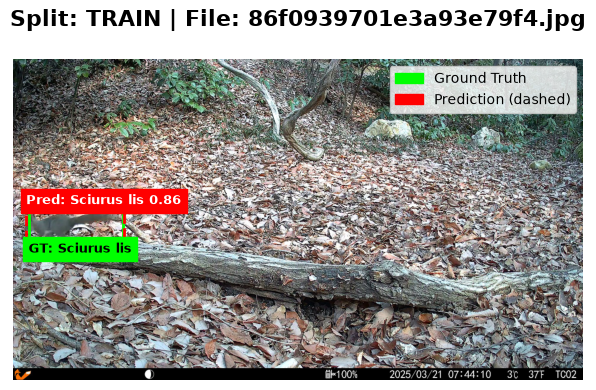

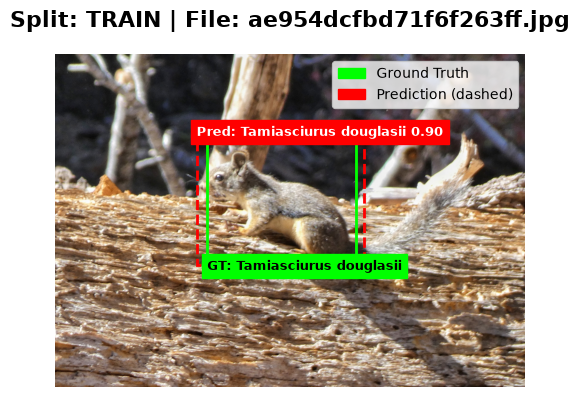

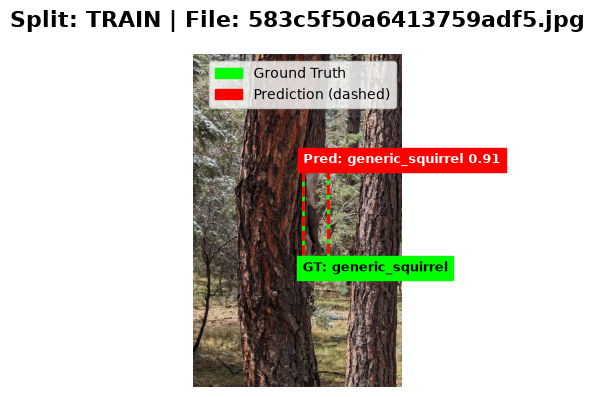

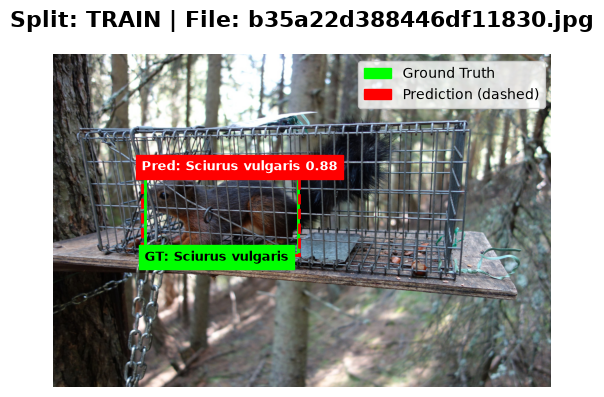

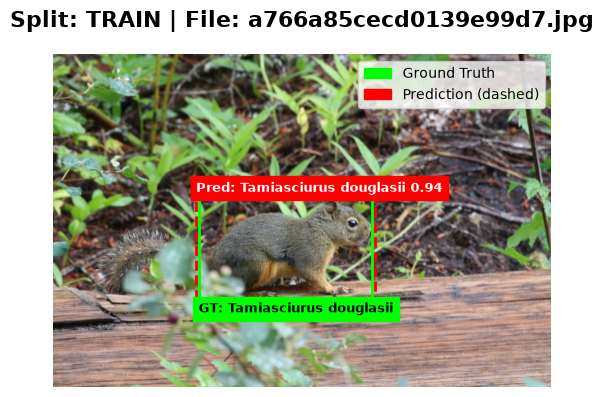


Evaluating random sample from VALID set...


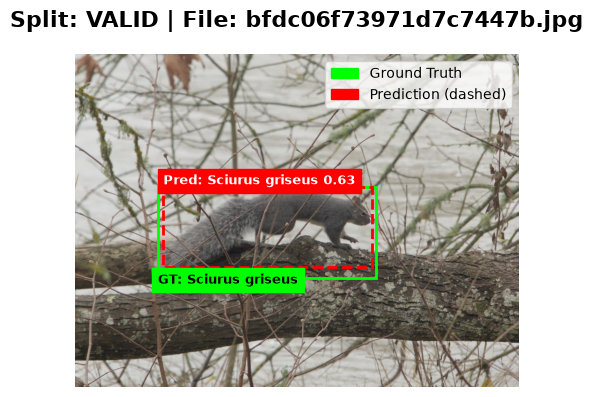

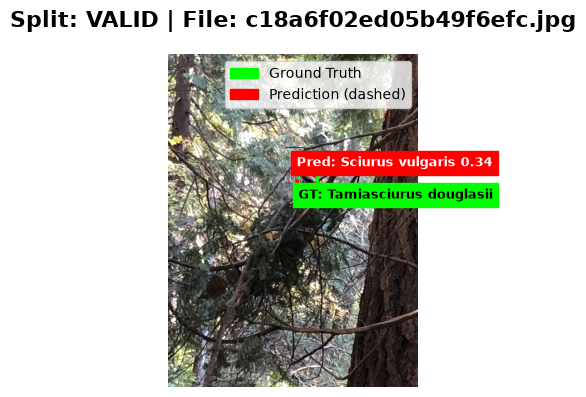

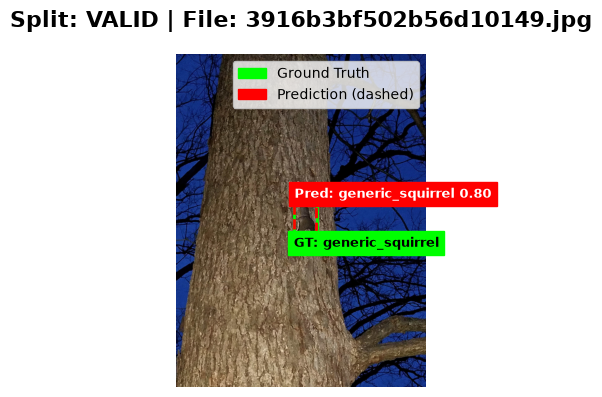

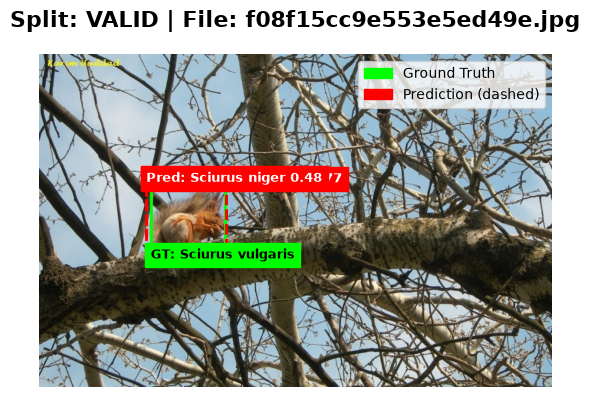

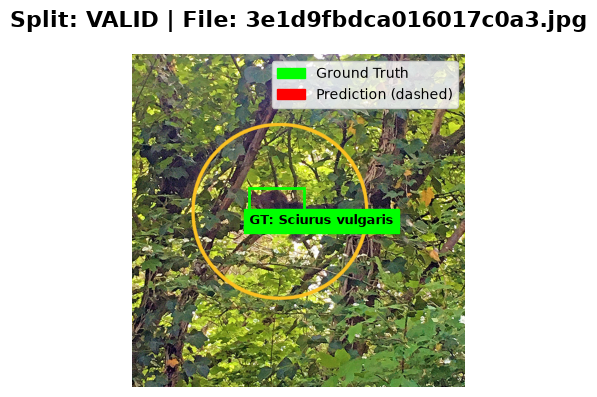


Evaluating random sample from TEST set...


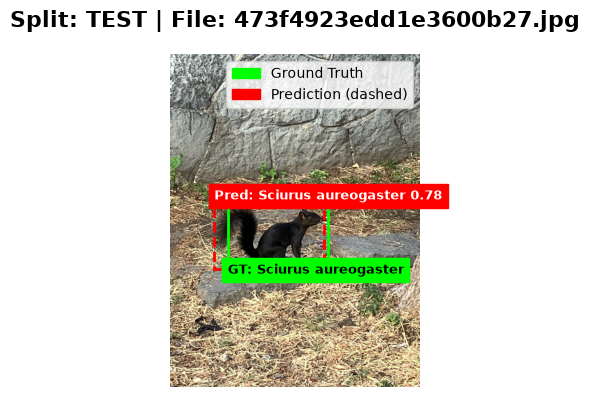

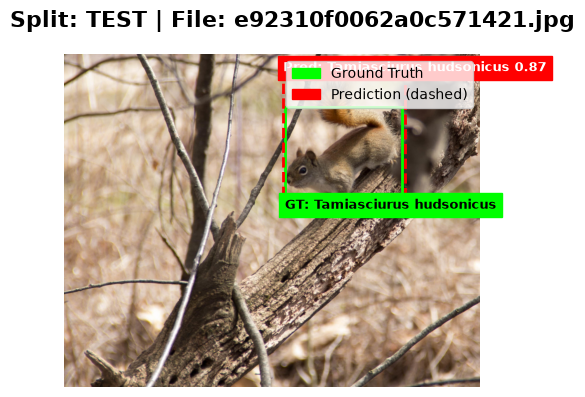

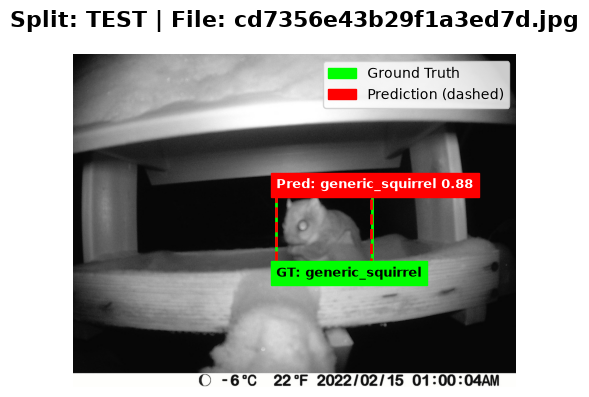

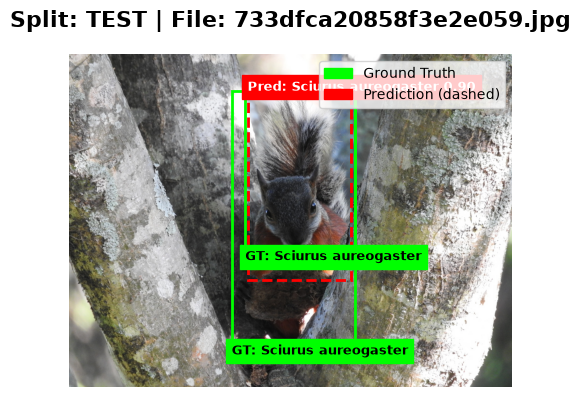

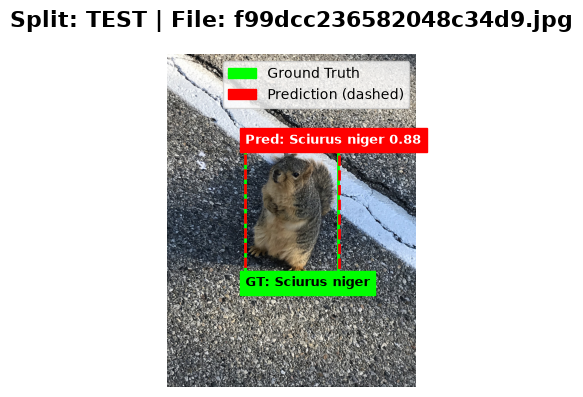

In [53]:
import os
import glob
import cv2
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def yolo_to_bbox(yolo_coords, img_width, img_height):
    """Converts YOLO normalized [x_center, y_center, w, h] to absolute [x_min, y_min, x_max, y_max]"""
    x_c, y_c, w, h = yolo_coords
    x_min = int((x_c - w / 2) * img_width)
    y_min = int((y_c - h / 2) * img_height)
    x_max = int((x_c + w / 2) * img_width)
    y_max = int((y_c + h / 2) * img_height)
    return x_min, y_min, x_max, y_max

def plot_gt_vs_pred_combined(split_name, num_samples=1):
    img_dir = os.path.join(data_dir, 'images', split_name)
    label_dir = os.path.join(data_dir, 'labels', split_name)
    
    all_images = glob.glob(os.path.join(img_dir, "*.jpg"))
    if not all_images:
        print(f"No images found for split: {split_name}")
        return
        
    sample_images = random.sample(all_images, min(num_samples, len(all_images)))
    
    for img_path in sample_images:
        # Load image
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w, _ = img.shape
        
        # Get Ground Truth
        base_name = os.path.splitext(os.path.basename(img_path))[0]
        label_path = os.path.join(label_dir, f"{base_name}.txt")
        gt_boxes = []
        if os.path.exists(label_path):
            with open(label_path, 'r') as f:
                for line in f:
                    parts = [float(x) for x in line.split()]
                    class_id = int(parts[0])
                    coords = parts[1:]
                    gt_boxes.append((class_id, yolo_to_bbox(coords, w, h)))
                    
        # Get Predictions
        results = model.predict(img_path, conf=0.25, verbose=False)[0]
        
        # Setup Figure - Single Plot
        fig, ax = plt.subplots(figsize=(6, 4))
        fig.suptitle(f"Split: {split_name.upper()} | File: {base_name}.jpg", fontsize=16, fontweight='bold')
        ax.imshow(img)
        ax.axis('off')
        
        # Plot Ground Truth (Solid Green, label at the BOTTOM to avoid overlap)
        for cls_id, (xmin, ymin, xmax, ymax) in gt_boxes:
            rect = patches.Rectangle((xmin, ymin), xmax-xmin, ymax-ymin, linewidth=2, edgecolor='lime', facecolor='none')
            ax.add_patch(rect)
            ax.text(xmin, ymax + 15, f"GT: {class_names[cls_id]}", color='black', fontsize=9, fontweight='bold', backgroundcolor='lime')
            
        # Plot Predictions (Dashed Red, label at the TOP)
        for box in results.boxes:
            xmin, ymin, xmax, ymax = map(int, box.xyxy[0].tolist())
            cls_id = int(box.cls[0].item())
            conf = box.conf[0].item()
            # Using dashed lines so a perfect prediction doesn't completely hide the green GT box
            rect = patches.Rectangle((xmin, ymin), xmax-xmin, ymax-ymin, linewidth=2, edgecolor='red', linestyle='--', facecolor='none')
            ax.add_patch(rect)
            label = f"Pred: {class_names[cls_id]} {conf:.2f}"
            ax.text(xmin, ymin - 8, label, color='white', fontsize=9, fontweight='bold', backgroundcolor='red')
            
        # Add custom legend
        handles = [
            patches.Patch(color='lime', label='Ground Truth'),
            patches.Patch(color='red', label='Prediction (dashed)')
        ]
        ax.legend(handles=handles, loc='upper right')
        
        plt.tight_layout()
        plt.show()

# Run the visualization
for split in ['train', 'valid', 'test']:
    print(f"\nEvaluating random sample from {split.upper()} set...")
    plot_gt_vs_pred_combined(split, num_samples=5)